In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np 
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from pathlib import Path
import os
from src.ekman import Ekman, EkmanConfig, Simulation, StateUpdater, rmse

from src.obsop import LinearObservationOperator


In [3]:
# --- Simulation Period
TTOT = 24 * 3600 # seconds

# --- True Parameters
UG_TRUE = 10    # m/s
K_TRUE = 2      # m^2/s

rng = np.random.default_rng(14)

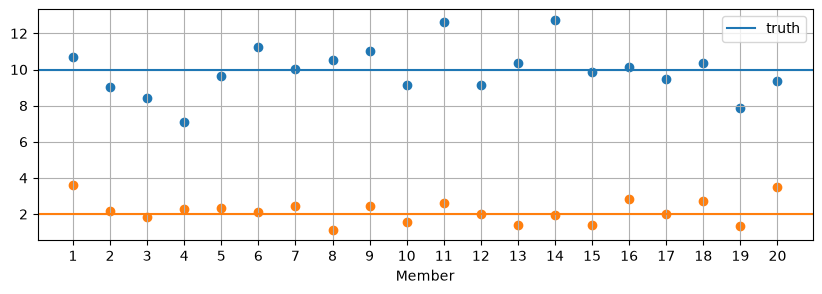

In [6]:
# ======================
# --- Ensemble SetUp
# ======================

# Ens Size 
N = 20

# Ensemble uncertainties
sigma_ug = 1
sigma_lnK = 0.35

## Independent perturbations
# -- Additive random noise for geo-wind
ug_ens = UG_TRUE + sigma_ug * rng.standard_normal(N)
vg_ens = np.zeros(N)
# -- Multiplicative log-normal noise for K
K_ens = K_TRUE * np.exp(sigma_lnK * rng.standard_normal(N))


fig,ax=plt.subplots(figsize=(10,3))
ax.scatter(np.arange(1,21, dtype=int), ug_ens, color="tab:blue")
ax.axhline(y=UG_TRUE, color="tab:blue", label="truth")
ax.scatter(np.arange(1,21, dtype=int), K_ens, color="tab:orange")
ax.axhline(y=K_TRUE, color="tab:orange")

ax.set_xlabel("Member")
ax.set_xticks([int(i) for i in range(1,21)])
ax.grid()
ax.legend()

In [7]:
# ====================
# --- TRUTH RUN
# ====================
SPINUP = 60 * 3600

config = EkmanConfig(spinup_seconds = SPINUP, output_interval = 60)
model_true = Ekman(ug=UG_TRUE, vg=0, K=K_TRUE, config=config)
model_true.spin_up()
sim_true = Simulation(model_true)
ds_true = sim_true.run(until=TTOT) # Control Forecast

In [ ]:
t0_assim = 3600
dt_assim = 7200
n_assim = 6
da_timer = [i for i in range(t0_assim, t0_assim+n_assim*dt_assim, dt_assim)] 


[3600, 10800, 18000, 25200, 32400, 39600]

In [ ]:
for i in range(N):

    ug = ug_ens[i]
    K = K_ens[i]
    print(f"SetUp Ekman-member with ug:{ug}, vg:{vg}, K:{K}")
    model = Ekman(ug=ug, vg=vg, K=K, config=config)
    model.spin_up()
    sim = Simulation(model)

    # --- Run DA-experiment
    analysis = sim.copy()
    # analysis_ds = analysis.run(until=3600)


    t = da_timer[0]

    # # -- Schedule 6 assimilation updates
    # for t in range(t0_assim, t0_assim+n_assim*dt_assim, dt_assim):

    # 1. Integrate to assimilation time
    analysis.run(until=t)

    # Get truth value
    utrue = ds_true.sel(time=t, z=H_OBS)["u"]
    vtrue = ds_true.sel(time=t, z=H_OBS)["v"]
    
    
    
    # # Extract current background forecast
    # idx = np.argmin(abs(analysis.model.z - H_OBS))
    # ubg = analysis.model.state.u[idx]
    # vbg = analysis.model.state.v[idx]
    # # Calculate increments
    # du = (utrue - ubg).item()
    # dv = (vtrue - vbg).item()
    # # Schedule assimilation
    # analysis.schedule(t,StateUpdater(du=du, dv=dv, h_obs=h_obs, sigma=sigma_obs))

    

    # # # --- Run simulation
    # ds_analysis = analysis.run(until=TTOT)

In [ ]:
"""Example: ensemble spin-up, background forecast, EnKF-shaped update, restart."""
import numpy as np
from ekman import EkmanConfig, EkmanEns, StateUpdater

config = EkmanConfig(nz=100, lz=500, spinup_seconds=600, output_interval=60)
ens = EkmanEns(ug=[8, 10, 12], vg=0, K=[1, 2, 4], config=config)
ens.spin_up()  # t0 = 0; each member has its own spun-up profile

# A scheduled model update is applied at a future time, for all members.
ens.schedule(600, StateUpdater(du=0.5, h_obs=100, sigma=25))
background = ens.run(until=1800)
print(background.sizes)                 # ensemble=3, time=..., z=101
print(ens.current().u.sel(z=100))        # Current u for all ensemble members

# A toy 'analysis' modifies ONLY interior u/v and the scalar K.
# Replace this with your own EnKF._analysis_step(...) return value.
analysis = ens.copy()
variables = ("u", "v", "K")
Xb = analysis.state_vector(variables)  # (3, 199) for nz=100
Xa = Xb.copy()
Xa[:, :config.nz - 1] += 0.2           # Toy increment to interior u(z)
Xa[:, -1] *= 1.1                       # Toy change to K
analysis.set_state_vector(Xa.reshape(3, 1, -1), variables)  # EnKF-style 3D output

# The parameter updates and analysis profiles are now in every member.
print("Posterior K:", analysis.current().K.values)
print("Control K:  ", ens.current().K.values)
result = analysis.run(until=3600)
print(result.u.dims)                    # ('ensemble', 'time', 'z')
print(result.time.values)               # 1D: common physical output times

 